## Intro

This notebook builds an implied volatility (IV) surface from a snapshot of SPY option prices (the ETF tracking the S&P 500), taken from Yahoo Finance on 2026-11-12.
To pull a new option chain, set 'REFRESH_DATA = True' and the notebook will retrieve the data at the time of running it
Specifically this notebook

- Checks data quality: missing or zero bid/asks, crossed quotes, wide spreads, duplicates, and timestamps  
- Filters to out-of-the-money options with moneyness (strike / spot) between 0.8 and 1.2, using mid prices
- Solves for IV with a bisection solver built on my own Black-Scholes pricer
- Plots the IV smile for an individual expiry, the skews across all expiries, and an interpolated 3D IV surface

In [84]:
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.interpolate import griddata

from black_scholes import implied_vol

# SETTINGS TO SPECIFY
TICKER = "SPY"
SNAPSHOT_DATE = "2026-11-12"        # date the chain was pulled (set to today's date when refreshing data)
SNAPSHOT_TIME_UTC = "16:41:24"      # approximate time of the pull
RISK_FREE_RATE = 0.04244            # risk-free rate as of 2026-11-12
REFRESH_DATA = False                # will pull a new chain from Yahoo Finance when True

DATA_DIR = Path("data")
IMAGE_DIR = Path("images")
DATA_DIR.mkdir(exist_ok=True)
IMAGE_DIR.mkdir(exist_ok=True)

RAW_PATH = DATA_DIR / f"{TICKER}_option_chain_{SNAPSHOT_DATE}.csv"


#### pulling the live data

In [85]:
def pull_option_chain(ticker_symbol):
    ### retrieving spot price (S)
    ticker = yf.Ticker(ticker_symbol)
    spot = ticker.history(period="1d")['Close'].iloc[-1]
    time_now = datetime.now(timezone.utc)

    ### retrieving time to expiry (T)
    # 1. set the variable days_to_ex as the time to expiry for all listed SPY options on yahoo finance 
    expiries = ticker.options  # selects all the expiration dates of the SPY options
    today = (pd.Timestamp.today().normalize())  # 'today' represents today's date normalized (i.e. DD/MM/YY at midnight)

    days_to_ex = {ex: (pd.Timestamp(ex) - today).days for ex in expiries}  # creates dictionary of the number of days to expiry for each expiration

    # 2. choose 8 different expiry times ranging from a week to 6 months (approx.) to use in plotting the 3D iv surface
    target_exs = [7, 30, 45, 60, 90, 120, 150, 180]  # 1week, 1month, 45days, 2months, 3months, 4months, 5months, 6months
    chosen = set()

    # for a given target t, scan all available options, find the one closest to the target ex date and add it to the set
    for t in target_exs:
        closest_expiry = None
        min_diff = float('inf')  # start with infinitely large difference
        
        for e in expiries:
            days = days_to_ex[e]  # how many days to expiry is this specific option
            diff = abs(days - t)  # how far is it from the target

            if diff < min_diff:
                min_diff = diff
                closest_expiry = e

        chosen.add(closest_expiry)

    chosen = sorted(list(chosen))

    ### creating option dataframe
    d_frames = []  # initialises empty list to store Dataframes as they are processed in the loop

    # loops through every option chain for each expiry and creates a dataframe for every option type
    for e in chosen:
        chain = ticker.option_chain(e)
        for df, option_type in ((chain.calls, "call"), (chain.puts, "put")):
            df = df.copy()  # creating safe copy of the DataFrame to avoid modifying the original data
            df["option_type"] = option_type  # add call/put column
            df["expiry"] = e  # add expiry column
            df["spot"] = spot  # add spot price column
            df["snapshot"] = time_now  # add timestamp for when snapshot was recorded column 
            d_frames.append(df)

    chains_df = pd.concat(d_frames, ignore_index=True)  # stacks all seperate dataframes into one, setting a new sequential index
    return chains_df

if REFRESH_DATA:
    if RAW_PATH.exists():
        raise FileExistsError(f"{RAW_PATH} already exists, change SNAPSHOT_DATE first")
    pull_option_chain(TICKER).to_csv(RAW_PATH, index=False)

#### creating dataframe for testing & cleaning

In [86]:
df = pd.read_csv(RAW_PATH)  # loading options dataset
r = RISK_FREE_RATE  

# creating columns for required variables / data sorting

df["mid"] = (df["bid"] + df["ask"]) / 2  # creating column for option mid-prices: C/P
df["moneyness"] = df["strike"] / df["spot"]  # column for moneyness axis on 3D surface (moneyness < 1: strike below spot, moneyness > 1: strike above spot)

# filtering out "bad data": options far from spot price have worse data (fewer trades so stale quotes, zero-bids, prices barely react to vol)
intervals = [0, 0.8, 0.95, 1.05, 1.2, 10]
labels=["<0.8", "0.8-0.95", "0.95-1.05", "1.05-1.2", ">1.2"]
df["zones"] = pd.cut(df["moneyness"], bins=intervals, labels=labels)  # column for moneyness-filtered options

# column for all OTM options (better quoted since mostly traded)
df["otm"] = ((df["option_type"] == 'call') & (df['spot'] < df['strike'])) | ((df['option_type'] == 'put') & (df['spot'] > df['strike']))   

# column for 'T' (years to expiry)
snapshot_date = pd.Timestamp(SNAPSHOT_DATE)
df['T'] = (pd.to_datetime(df['expiry']) - snapshot_date).dt.days / 365



#### data validity checks

In [87]:
# zero / missing bid/ask quote
df['bad_quote'] = df['bid'].isna() | df['ask'].isna() | (df['bid'] == 0) | (df['ask'] == 0)  # isna() detects missing value
df.groupby('zones', observed=True)['bad_quote'].mean()  # mean value of bad quotes for each zone 

zones
<0.8         0.102970
0.8-0.95     0.000000
0.95-1.05    0.000000
1.05-1.2     0.014423
>1.2         0.446429
Name: bad_quote, dtype: float64

In [88]:
# crossed quotes - ask should be > bid
print(((df['bid'] > df['ask']) & (df['ask'] > 0) & (df['bid'] > 0)).sum())  # how many crossed quotes
print(df[(df['bid'] > df['ask']) & (df['ask'] > 0) & (df['bid'] > 0)])  # at which row

0
Empty DataFrame
Columns: [contractSymbol, lastTradeDate, strike, lastPrice, bid, ask, change, percentChange, volume, openInterest, impliedVolatility, inTheMoney, contractSize, currency, option_type, expiry, spot, snapshot, mid, moneyness, zones, otm, T, bad_quote]
Index: []

[0 rows x 24 columns]


In [89]:
# wide spreads - check as a proportion of mid-price to ascertain whether mid-price is suitable fair price or not
valid = df[df['mid'] > 0].copy()  # dataframe of mid-prices greater than zero for valid division
valid['spread_to_mid'] = (valid['ask'] - valid['bid']) / valid['mid']  # checking spread / mid-price
valid.groupby('zones', observed=True)['spread_to_mid'].median()  # viewing the median spread : mid-price ration for each zone

zones
<0.8         0.016163
0.8-0.95     0.019417
0.95-1.05    0.009276
1.05-1.2     0.038462
>1.2         0.666667
Name: spread_to_mid, dtype: float64

In [90]:
# duplicates
df.duplicated('contractSymbol').sum()

np.int64(0)

In [91]:
# strike coverage - whether the surface will have enough points inside 0.8-1.2 interval for each expiry
print(df.groupby('expiry')['moneyness'].agg(['min', 'max', 'count']))  # calculates lowest, highest moneyness and number of contracts for each expiry
print(df[df['moneyness'].between(0.8, 1.2)].groupby(['expiry', 'option_type']).size())  # how many calls and puts there are for each expiry within the moneyness interval

                 min       max  count
expiry                               
2026-11-19  0.907369  1.091473     53
2026-12-11  0.657514  1.222976    244
2026-12-24  0.657514  1.163800    142
2027-01-15  0.065751  1.946242    419
2027-02-19  0.526011  1.249277    174
2027-03-19  0.328757  1.946242    337
2027-04-16  0.328757  1.249277     79
2027-04-30  0.696965  1.196676    245
expiry      option_type
2026-11-19  call            29
            put             24
2026-12-11  call           117
            put             89
2026-12-24  call            65
            put             63
2027-01-15  call            61
            put             58
2027-02-19  call            59
            put             45
2027-03-19  call            61
            put             60
2027-04-16  call            27
            put             31
2027-04-30  call           122
            put            109
dtype: int64


In [92]:
# check T is correct
df.groupby("expiry")["T"].first() * 365  # checking the day count mathces calendar days from snapshot to expiry

expiry
2026-11-19      7.0
2026-12-11     29.0
2026-12-24     42.0
2027-01-15     64.0
2027-02-19     99.0
2027-03-19    127.0
2027-04-16    155.0
2027-04-30    169.0
Name: T, dtype: float64

In [93]:
# how many usable rows survive per expiry 
usable = df[df["otm"] & (df["bid"] > 0) & df["moneyness"].between(0.8, 1.2)]
usable.groupby("expiry").size()

expiry
2026-11-19     29
2026-12-11    121
2026-12-24     80
2027-01-15     61
2027-02-19     61
2027-03-19     61
2027-04-16     46
2027-04-30    122
dtype: int64

In [94]:
# date format and timezone
snap = pd.Timestamp(f"{SNAPSHOT_DATE} {SNAPSHOT_TIME_UTC}", tz="UTC")
last_trade = pd.to_datetime(df["lastTradeDate"], utc=True)

print(df[["lastTradeDate", "snapshot"]].head())
print(last_trade.min(), last_trade.max(), snap)  
print("latest trade minus snapshot:", last_trade.max() - snap)  # checks no trades are 'in the future' as this would signal a timezone mismatch (should return negative)


               lastTradeDate         snapshot
0  2026-11-09 15:23:07+00:00  16:41:24.096758
1  2026-11-06 14:47:08+00:00  16:41:24.096758
2  2026-11-09 14:52:09+00:00  16:41:24.096758
3  2026-11-06 14:47:09+00:00  16:41:24.096758
4  2026-11-09 15:17:13+00:00  16:41:24.096758
2025-05-30 14:52:27+00:00 2026-11-12 16:26:10+00:00 2026-11-12 16:41:24+00:00
latest trade minus snapshot: -1 days +23:44:46


count    1693.000000
mean        0.312913
std         0.314872
min         0.000010
25%         0.140870
50%         0.211022
75%         0.390173
max         3.364504
Name: impliedVolatility, dtype: float64
98
Axes(0.125,0.11;0.775x0.77)


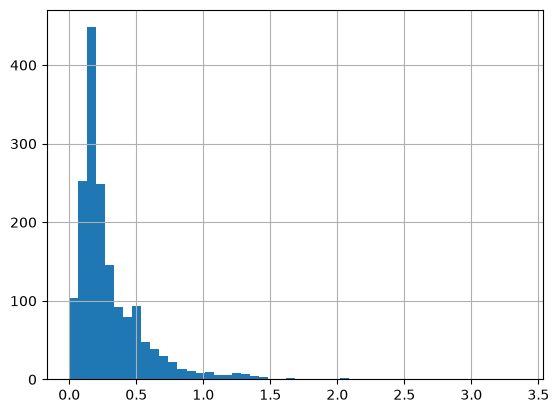

In [95]:
# check Yahoo's implied vol - for reference post-plot
print(df["impliedVolatility"].describe())
print((df["impliedVolatility"] < 0.01).sum())
print(df["impliedVolatility"].hist(bins=50))

#### 3D surface

##### filtering

In [96]:
# creating new dataframe

clean_df = pd.read_csv(RAW_PATH).copy()

# adding mid, moneyness, T columns to new csv copy
clean_df['mid'] = (clean_df['ask'] + clean_df['bid']) / 2
clean_df['moneyness'] = clean_df['strike'] / clean_df['spot']
clean_df['T'] = (pd.to_datetime(clean_df['expiry']) - snapshot_date).dt.days / 365


# function for live row count after each cleaning stage
steps = []
def row_count(stage, d):
    steps.append((stage, len(d)))
    return d  # returning the filtered dataframe back out

# filters
clean_df = row_count('start', clean_df)
clean_df = row_count('cut missing bid/ask', clean_df.dropna(subset=['bid', 'ask']))
clean_df = row_count('keep bid > 0', clean_df[clean_df['bid'] > 0])
clean_df = row_count('keep ask > 0', clean_df[clean_df['ask'] > 0])
clean_df = row_count('keep bid <= ask', clean_df[clean_df['bid'] <= clean_df['ask']])

OTM_condition = ((clean_df['option_type'] == 'call') & (clean_df['spot'] < clean_df['strike'])) | ((clean_df['option_type'] == 'put') & (clean_df['spot'] > clean_df['strike']))
clean_df = row_count('keep only OTM', clean_df[OTM_condition])
clean_df = row_count('keep moneyness between 0.8-1.2', clean_df[clean_df['moneyness'].between(0.8, 1.2)])
clean_df = row_count(' cut duplicates', clean_df.drop_duplicates('contractSymbol'))
clean_df = clean_df.reset_index(drop=True)

pd.DataFrame(steps, columns=['stage', 'row count'])


,stage,row count
0,start,1693
1,cut missing bid/ask,1693
2,keep bid > 0,1564
3,keep ask > 0,1563
4,keep bid <= ask,1563
5,keep only OTM,912
6,keep moneyness between 0.8-1.2,581
7,cut duplicates,581


##### solving

In [97]:
# solve
from black_scholes import implied_vol


clean_df['iv'] = clean_df.apply(lambda row: implied_vol(row['mid'], row['spot'], row['strike'], row['T'], r, row['option_type']), axis=1)
print("nan count:", clean_df["iv"].isna().sum())
clean_df = clean_df.dropna(subset=['iv'])
clean_df["iv"].describe()

nan count: 0


count    581.000000
mean       0.174617
std        0.053942
min        0.114602
25%        0.130797
50%        0.158098
75%        0.204945
max        0.376519
Name: iv, dtype: float64

In [98]:
# comparing with Yahoo iv
(clean_df['iv'] - clean_df['impliedVolatility']).describe()
print("correlation:", clean_df["iv"].corr(clean_df["impliedVolatility"]))

correlation: 0.945689474467223


##### plotting 2D smiles

In [99]:
import matplotlib.pyplot as plt

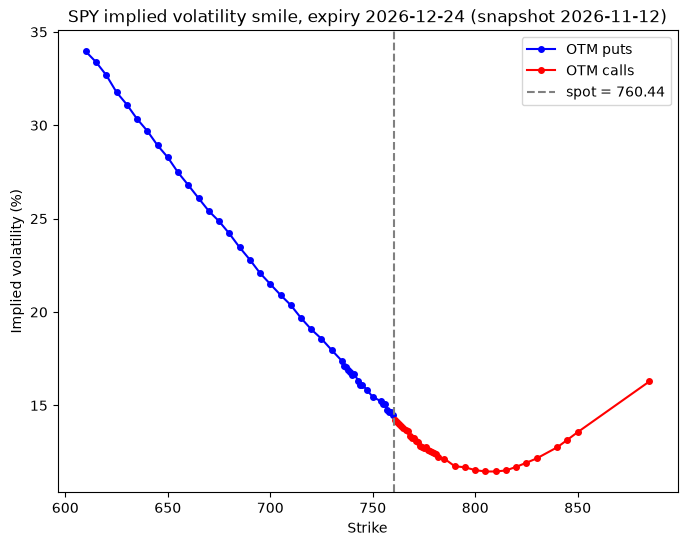

In [100]:
# plotting for one expiry
expiry = "2026-12-24"
one_values = clean_df[clean_df['expiry'] == expiry].sort_values('strike')  # one_values dataframe with only "2026-12-24" expiries sorted by strike price
spot = one_values['spot'].iloc[0]

fig, ax = plt.subplots(figsize=(8,6))
for opt_type, colour in (('put', 'b'), ('call', 'r')):
    df_part = one_values[one_values['option_type'] == opt_type]  # choosing option type
    ax.plot(df_part['strike'], df_part['iv'] * 100, marker='o', markersize=4, color=colour, label=f'OTM {opt_type}s')  # plotting strike against iv
ax.axvline(spot, linestyle="--", color="grey", label=f"spot = {spot:.2f}")  # spot value to see ATM options 
ax.set_xlabel("Strike")
ax.set_ylabel("Implied volatility (%)")
ax.set_title(f"SPY implied volatility smile, expiry {expiry} (snapshot 2026-11-12)")
ax.legend()
fig.savefig(IMAGE_DIR / f"smile_{expiry}.png", dpi=150)
plt.show()

In [101]:
# save clean_df
clean_df.to_csv(DATA_DIR / f"{TICKER}_cleaned_iv_{SNAPSHOT_DATE}.csv", index=False)

In [102]:
# creating plot dataframe for all expiries (expiry, T, strike, moneyness K/S, implied vol)

# create list to hold dataframes for each expiry
plot_data_list = [] 
for e in clean_df['expiry'].unique():
    # filter rows for current expiry
    sub_df = clean_df[clean_df['expiry'] == e].copy()
    sub_df['T'] = (pd.to_datetime(sub_df['expiry']) - snapshot_date) / pd.Timedelta(days=365)
    sub_df['moneyness'] = sub_df['strike'] / sub_df['spot']
    clean_subset = sub_df[['expiry', 'T', 'strike', 'moneyness', 'iv']].copy()

    plot_data_list.append(clean_subset)
# combine expiry dataframes into one
plot_df = pd.concat(plot_data_list, ignore_index=True)


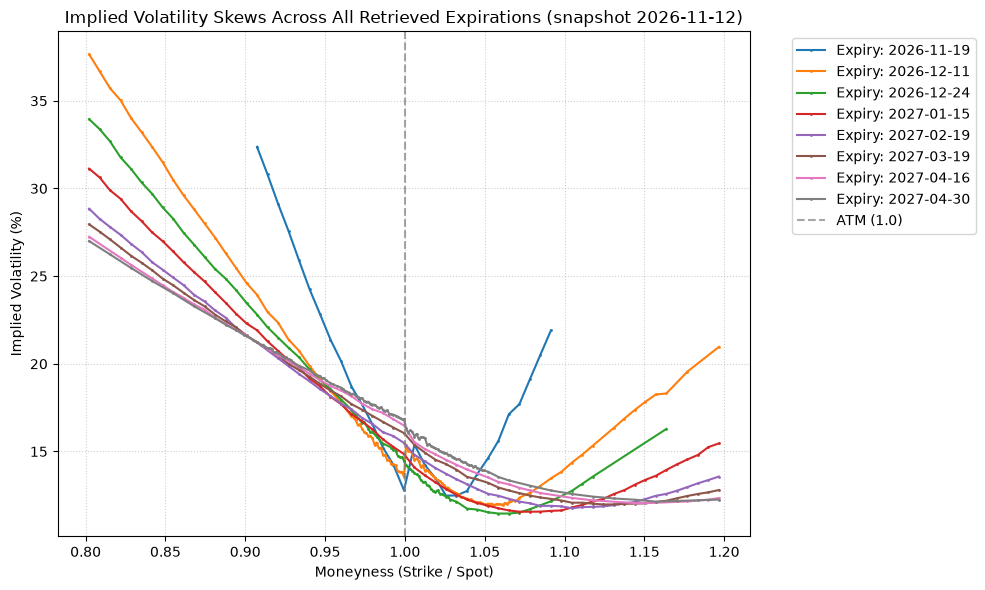

In [103]:
# volatility smiles for all expiries
fig, ax = plt.subplots(figsize=(10,6))

for e in plot_df['expiry'].unique():
    df_part = plot_df[plot_df['expiry'] == e].sort_values('moneyness')
    ax.plot(df_part['moneyness'], df_part['iv'] * 100, marker='o', markersize=1, label=f"Expiry: {e}")

ax.set_title("Implied Volatility Skews Across All Retrieved Expirations (snapshot 2026-11-12)")
ax.set_xlabel("Moneyness (Strike / Spot)")
ax.set_ylabel("Implied Volatility (%)")

# Since moneyness K/S is on the x-axis, At-The-Money is at 1.0
ax.axvline(1.0, linestyle="--", color="grey", alpha=0.7, label="ATM (1.0)")

ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # legend outside box
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
fig.savefig(IMAGE_DIR / "iv_skews_all_expiries.png", dpi=150)
plt.show()

In [104]:
# investigating the 1-week spike

one_wk = df[(df['expiry'] == '2026-11-19') & df['moneyness'].between(0.97, 1.05) & (df['bid'] > 0)].copy()
one_wk['iv'] = one_wk.apply(lambda row: implied_vol(row['mid'], row['spot'], row['strike'], row['T'], r, row['option_type']), axis=1)

cmp = one_wk.pivot_table(index='strike', columns='option_type', values=['iv', 'mid', 'volume'])
cmp[('iv', 'call - put')] = (cmp[('iv', 'call')] - cmp[('iv', 'put')]) * 100   # in percentage points
cmp

iv               mid         volume                 iv
option_type      call       put    call     put   call     put call - put
strike                                                                   
740.0        0.251004  0.176840  24.135   1.150    2.0  1037.0   7.416338
745.0        0.213621  0.165426  19.115   1.635   12.0   513.0   4.819503
750.0        0.202761  0.152211  15.105   2.295   28.0   236.0   5.054912
755.0        0.185075  0.142285  11.145   3.410  928.0   590.0   4.278970
760.0        0.170271  0.127852   7.690   4.855  984.0   515.0   4.241936
765.0        0.153829  0.116496   4.700   7.125  284.0   114.0   3.733278
770.0        0.142220  0.094753   2.570   9.960  126.0    18.0   4.746750
775.0        0.134701       NaN   1.255  13.525  234.0     3.0        NaN
780.0        0.124844       NaN   0.465  17.825   64.0     1.0        NaN
785.0        0.124874       NaN   0.195  22.810    4.0     1.0        NaN
790.0        0.127460       NaN   0.085  27.755   21.0    14.0        NaN
795.0        0.137314       NaN   0.055  32.945    5.0     2.0        NaN

##### 3D surface

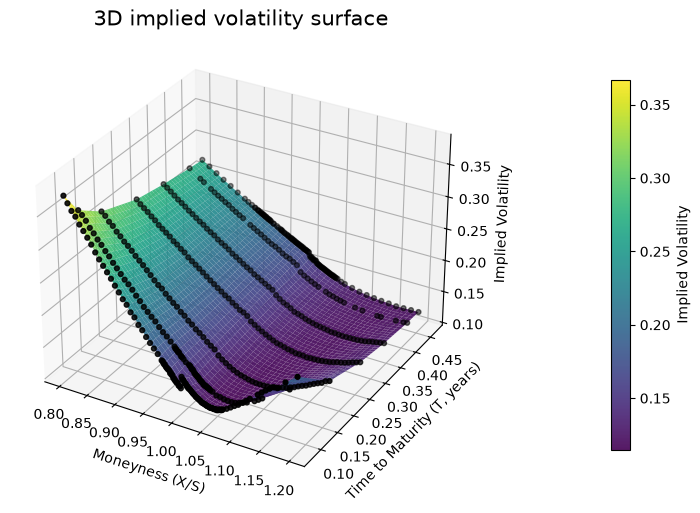

In [106]:
from scipy.interpolate import griddata

# removing 1-week expiry data due to noisy quotes
plot_df = plot_df[plot_df['expiry'] != '2026-11-19']

# creating (x, y) coord pairs with (moneyness, T)
points = np.column_stack((plot_df['moneyness'], plot_df['T']))  
values = plot_df['iv'].to_numpy()

# create evenly spaced 2D grid for moneyness and T
m_1d = np.linspace(plot_df['moneyness'].min(), plot_df['moneyness'].max(), 50)
t_1d = np.linspace(plot_df['T'].min(), plot_df['T'].max(), 50)
M_grid, T_grid = np.meshgrid(m_1d, t_1d)  # creates 2 grids ('sheets'), one to plot moneyness value and one for T

IV_grid = griddata(points, plot_df['iv'], (M_grid, T_grid), method='linear')

fig = plt.figure(figsize=(18, 6))
ax = fig.add_subplot(projection='3d')

surf = ax.plot_surface(
    M_grid, T_grid, IV_grid,
    cmap='viridis',
    edgecolor='none',
    alpha=0.9
)

ax.scatter(plot_df['moneyness'], plot_df['T'], plot_df['iv'], color='black', s=12, label='observed points')  # scattered points overlayed on surface

ax.set_xlabel('Moneyness (X/S)')
ax.set_ylabel('Time to Maturity (T, years)')
ax.set_zlabel('Implied Volatility')
fig.colorbar(surf, shrink=0.8, pad=0.1, label='Implied Volatility')
ax.set_title('3D implied volatility surface', size=15)
fig.savefig(IMAGE_DIR / "iv_surface_3d.png", dpi=150)
plt.show()